<>:41: SyntaxWarning: invalid escape sequence '\l'
<>:42: SyntaxWarning: invalid escape sequence '\l'
<>:41: SyntaxWarning: invalid escape sequence '\l'
<>:42: SyntaxWarning: invalid escape sequence '\l'
C:\Users\andri\AppData\Local\Temp\ipykernel_28948\2731931189.py:41: SyntaxWarning: invalid escape sequence '\l'
  ax.set_xlabel("Numero di Contributi (Scala Logaritmica $\log_{10}$)", fontsize=11)
C:\Users\andri\AppData\Local\Temp\ipykernel_28948\2731931189.py:42: SyntaxWarning: invalid escape sequence '\l'
  ax.set_ylabel("P(X > x) - Probabilità Cumulativa (Scala Logaritmica $\log_{10}$)", fontsize=11)


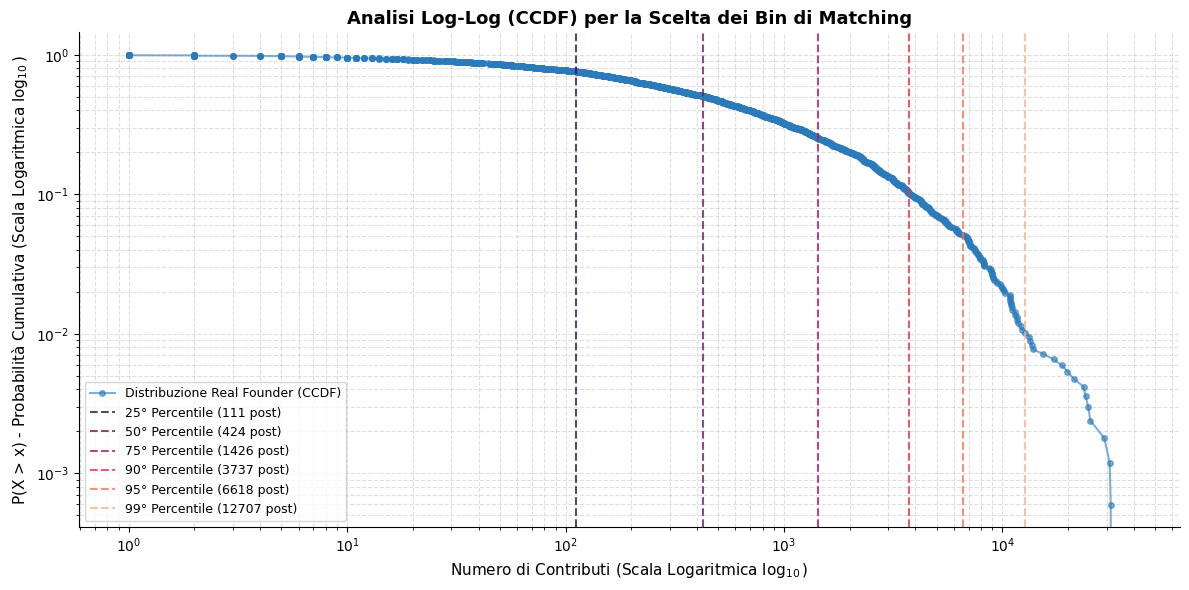

Founder con ESATTAMENTE 0 contributi: 25 (1.5%)

VALORI CHIAVE DEI PERCENTILI
 25 Percentile: 111 post

 50 Percentile: 424 post

 75 Percentile: 1426 post

 90 Percentile: 3737 post

 95 Percentile: 6618 post

 99 Percentile: 12707 post

Distribuzione con Bin Fissi Empirici:
Intervallo Bin          Num Founder     Percentuale
(-0.001, 50.0]          271             15.9%
(50.0, 200.0]           335             19.7%
(200.0, 500.0]          310             18.2%
(500.0, 1000.0]         246             14.4%
(1000.0, 2500.0]        263             15.4%
(2500.0, 38378.0]       278             16.3%
Distribuzione basata sui Quantili:
Intervallo Bin          Num Founder     Percentuale

(-0.001, 1.0]           38              2.2%

(1.0, 424.0]            814             47.8%

(424.0, 1426.0]         425             25.0%

(1426.0, 3737.0]        255             15.0%

(3737.0, 38378.0]       171             10.0%



In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# Carichiamo il dataset pulito a 3 mesi
path_dataset = "../data/interim/foundersFeatures_FINAL.csv"
df = pd.read_csv(path_dataset, index_col=0)

# Estraiamo i contributi reali (rimuovendo eventuali NaN residui)
contributions = df['num contributions'].dropna().values

# Separazione fondamentale: gli utenti con 0 post vanno gestiti con cura
zeros_count = np.sum(contributions == 0)
positives = contributions[contributions > 0]
positives_sorted = np.sort(positives)

# Calcoliamo i quantili specchio per capire dove si concentra la popolazione
quantiles_pct = [25, 50, 75, 90, 95, 99]
quantiles_vals = np.percentile(contributions, quantiles_pct)


n_pos = len(positives_sorted)
ccdf = 1.0 - (np.arange(1, n_pos + 1) / n_pos)

fig, ax = plt.subplots(figsize=(12, 6))

# Tracciamento della curva di distribuzione log-log
ax.loglog(positives_sorted, ccdf, marker='o', linestyle='-', color='#2b7bba', 
          alpha=0.6, markersize=4, label='Distribuzione Real Founder (CCDF)')

# Proiettiamo i quantili come linee verticali tratteggiate
colors = sns.color_palette("rocket", len(quantiles_pct))
for pct, val, col in zip(quantiles_pct, quantiles_vals, colors):
    if val > 0: # Il logaritmo di 0 non è definibile sull'asse X logaritmico
        ax.axvline(x=val, color=col, linestyle='--', alpha=0.8, 
                   label=f'{pct}° Percentile ({int(val)} post)')

ax.set_title("Analisi Log-Log (CCDF) per la Scelta dei Bin di Matching", fontsize=13, fontweight='bold')
ax.set_xlabel("Numero di Contributi (Scala Logaritmica $\log_{10}$)", fontsize=11)
ax.set_ylabel("P(X > x) - Probabilità Cumulativa (Scala Logaritmica $\log_{10}$)", fontsize=11)
ax.grid(True, which="both", ls="--", alpha=0.4)
ax.legend(loc='lower left', fontsize=9, frameon=True)
sns.despine()
plt.tight_layout()
plt.show()


print(f"Founder con ESATTAMENTE 0 contributi: {zeros_count} ({zeros_count/len(contributions)*100:.1f}%)\n")

print("VALORI CHIAVE DEI PERCENTILI")
for pct, val in zip(quantiles_pct, quantiles_vals):
    print(f" {pct} Percentile: {int(val)} post\n")

# Simulazione con Bin Logaritmici Fissi Empirici
edges_fissi = [0, 50, 200, 500, 1000, 2500, int(contributions.max())]
df['bin_fisso'] = pd.cut(df['num contributions'], bins=edges_fissi, include_lowest=True)
counts_fissi = df['bin_fisso'].value_counts().sort_index()

print("Distribuzione con Bin Fissi Empirici:")
print(f"{'Intervallo Bin':<22}  {'Num Founder':<14}  {'Percentuale':<10}")
for interval, count in counts_fissi.items():
    print(f"{str(interval):<22}  {count:<14}  {(count/len(contributions))*100:.1f}%")

# Simulazione con Bin basati sui Quantili Reali (Arrotondati)
edges_quantili = [0, 1, int(quantiles_vals[1]), int(quantiles_vals[2]), int(quantiles_vals[3]), int(contributions.max())]
# Rimuoviamo eventuali duplicati se i quantili bassi schiacciano lo stesso valore
edges_quantili = sorted(list(set(edges_quantili))) 

df['bin_quantile'] = pd.cut(df['num contributions'], bins=edges_quantili, include_lowest=True)
counts_quantili = df['bin_quantile'].value_counts().sort_index()

print("Distribuzione basata sui Quantili:")
print(f"{'Intervallo Bin':<22}  {'Num Founder':<14}  {'Percentuale':<10}\n")
for interval, count in counts_quantili.items():
    print(f"{str(interval):<22}  {count:<14}  {(count/len(contributions))*100:.1f}%\n")